Sensor LSB ≈ 1.526 µT, using u_B_sensor ≈ 0.763 µT per reading
Background field: 5.300 µT
Using current I = 3.0000 A
   position y (cm)  B(y) (micro tesla)  actual current
0                0           1180.5000               3
1                2           2993.4001               3
2                4           3357.3000               3
3                6           3359.4001               3
4                8           3404.1000               3
5               10           3357.6000               3
6               12           3357.3000               3
7               14           3172.2001               3
8               16           2125.8000               3

--- Task 1 key results (experimental, background-corrected) ---
Left end (z≈0.000 m):  B_end,left = 1175.20 ± 1.08 µT
Right end (z≈0.160 m): B_end,right= 2120.50 ± 1.08 µT
Center (z=0.080 m):  B_center   = 3398.80 ± 1.08 µT (interp.)

--- Theory at same points (Monte Carlo with geom+I uncertainty) ---
Theory left end:  1761.60 ± 2

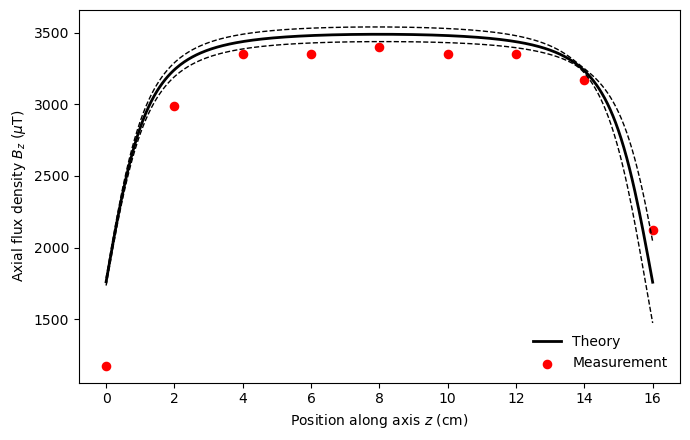

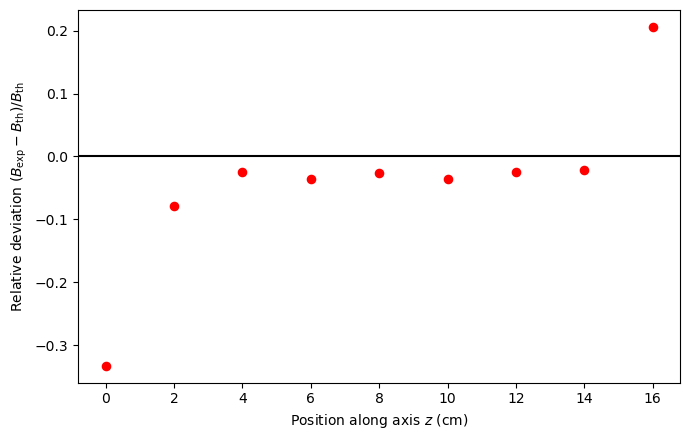

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# 0) Constants and coil params
# -----------------------------
mu0 = 4*np.pi*1e-7  # H/m

# Solenoid 3 (from manual table)
L0 = 160e-3   # m
R0 = 13e-3    # m
N  = 150

# Uncertainties from manual
rel_u_geom = 0.015  # 1.5% for L and R

# Power supply current uncertainty (manual): ±(0.05% + 3 mA)
def u_I_supply(I_A: float) -> float:
    return 0.0005*I_A + 0.003  # A

# Sensor resolution (manual): 16-bit, configured to ±50 mT => span = 100 mT
# LSB = 100 mT / 65536 = 1.5259 µT
lsb_uT = 100e3 / 65536  # µT
# Use ±0.5 LSB as an effective 1σ measurement uncertainty (simple, conservative)
u_B_sensor_uT = 0.5 * lsb_uT  # µT

print(f"Sensor LSB ≈ {lsb_uT:.3f} µT, using u_B_sensor ≈ {u_B_sensor_uT:.3f} µT per reading")

# ---------------------------------
# 1) Load CSV robustly + parse data
# ---------------------------------
csv_path = "Task 1.csv"  # adjust if needed

# Try common separators
for sep in [",", ";", "\t"]:
    try:
        df_raw = pd.read_csv(csv_path, sep=sep)
        if df_raw.shape[1] >= 2:
            break
    except Exception:
        continue

df = df_raw.copy()
df.columns = [c.strip() for c in df.columns]

# Expected columns (as in your screenshot)
# 'position y (cm)', 'B(y) (micro tesla)', 'set current', 'actual current'
pos_col = [c for c in df.columns if "position" in c.lower()][0]
B_col   = [c for c in df.columns if "b(" in c.lower() or "micro" in c.lower()][0]
Iact_col = [c for c in df.columns if "actual" in c.lower()][0] if any("actual" in c.lower() for c in df.columns) else None

# Background row (position contains 'background')
bg_mask = df[pos_col].astype(str).str.lower().str.contains("background")
if bg_mask.any():
    B_bg_uT = float(df.loc[bg_mask, B_col].iloc[0])
else:
    # fallback: assume last row is background if position is non-numeric
    # (works if the last row is background)
    try:
        B_bg_uT = float(df[B_col].iloc[-1])
    except Exception:
        raise ValueError("Couldn't find a background row. Please ensure one row contains 'background' in the position column.")

# Numeric measurement rows (positions are numeric)
df_meas = df.loc[~bg_mask].copy()
df_meas[pos_col] = pd.to_numeric(df_meas[pos_col], errors="coerce")
df_meas[B_col]   = pd.to_numeric(df_meas[B_col], errors="coerce")
if Iact_col is not None:
    df_meas[Iact_col] = pd.to_numeric(df_meas[Iact_col], errors="coerce")

df_meas = df_meas.dropna(subset=[pos_col, B_col]).sort_values(pos_col).reset_index(drop=True)

# Extract arrays
z_cm = df_meas[pos_col].to_numpy()
z_m  = z_cm * 1e-2

B_meas_uT = df_meas[B_col].to_numpy()
B_corr_uT = B_meas_uT - B_bg_uT  # background subtraction

# Current: use actual current column if present and valid, else use 3 A
if Iact_col is not None and np.isfinite(df_meas[Iact_col]).all():
    I_A = float(np.mean(df_meas[Iact_col]))
else:
    I_A = 3.0

print(f"Background field: {B_bg_uT:.3f} µT")
print(f"Using current I = {I_A:.4f} A")
print(df_meas[[pos_col, B_col] + ([Iact_col] if Iact_col else [])])

# -------------------------------------------------
# 2) Theory: finite solenoid axial field Bz(z = a)
# -------------------------------------------------
def Bz_solenoid_finite(a_m, I_A, L_m, R_m, N_turns):
    """
    Axial flux density Bz along the axis of a finite solenoid.
    Coordinate a measured from the left end (a=0 at left end, a=L at right end).
    Based on the manual's solenoid expression (finite-length result).
    """
    n = N_turns / L_m
    term1 = a_m / np.sqrt(R_m**2 + a_m**2)
    term2 = (L_m - a_m) / np.sqrt(R_m**2 + (L_m - a_m)**2)
    return (mu0 * n * I_A / 2.0) * (term1 + term2)  # Tesla

# Dense z grid for smooth theoretical curve
z_grid = np.linspace(np.min(z_m), np.max(z_m), 400)
B_th_T = Bz_solenoid_finite(z_grid, I_A, L0, R0, N)
B_th_uT = B_th_T * 1e6

# ------------------------------------------
# 3) Uncertainties: Monte Carlo for theory
# ------------------------------------------
rng = np.random.default_rng(0)

n_mc = 20000

# Geometry uncertainties (1.5% relative)
L_samp = rng.normal(L0, rel_u_geom*L0, size=n_mc)
R_samp = rng.normal(R0, rel_u_geom*R0, size=n_mc)

# Current uncertainty from power supply spec
uI = u_I_supply(I_A)
I_samp = rng.normal(I_A, uI, size=n_mc)

# Compute theory band on grid
B_mc = np.empty((n_mc, z_grid.size), dtype=float)
for k in range(n_mc):
    # Prevent non-physical negative samples (rare but possible)
    Lk = max(L_samp[k], 1e-6)
    Rk = max(R_samp[k], 1e-6)
    Ik = max(I_samp[k], 0.0)
    B_mc[k, :] = Bz_solenoid_finite(z_grid, Ik, Lk, Rk, N)

B_th_mean_uT = (B_mc.mean(axis=0))*1e6
B_th_std_uT  = (B_mc.std(axis=0, ddof=1))*1e6  # 1σ band

# ------------------------------------------
# 4) Experimental uncertainties (sensor + bg)
# ------------------------------------------
# Treat each reading as having sensor uncertainty u_B_sensor_uT
# Background measured once, subtracting it adds in quadrature:
u_Bcorr_uT = np.sqrt(u_B_sensor_uT**2 + u_B_sensor_uT**2)  # same sensor used => simple assumption

# ------------------------------------------
# 5) Extract required quantities for Task 1
# ------------------------------------------
# End fields: left end at z=0, right end at z=L (your data includes 0 and 16 cm)
# Use nearest points:
def nearest_value(z_array, y_array, z0):
    idx = int(np.argmin(np.abs(z_array - z0)))
    return y_array[idx], z_array[idx]

B_end_left_uT, zL_end = nearest_value(z_m, B_corr_uT, 0.0)
B_end_right_uT, zR_end = nearest_value(z_m, B_corr_uT, L0)

# Center field at z=L/2: interpolate from measurements
z_center = L0/2
B_center_uT = np.interp(z_center, z_m, B_corr_uT)

# Theory at same points (use mean geometry values)
B_end_left_th_uT  = Bz_solenoid_finite(0.0,     I_A, L0, R0, N)*1e6
B_end_right_th_uT = Bz_solenoid_finite(L0,      I_A, L0, R0, N)*1e6
B_center_th_uT    = Bz_solenoid_finite(z_center,I_A, L0, R0, N)*1e6

# Uncertainty for theoretical values at specific points (from MC)
def mc_stats_at(a_val):
    # Compute MC at a single a_val for speed/precision
    Bvals = np.array([Bz_solenoid_finite(a_val, max(I_samp[k],0.0), max(L_samp[k],1e-6), max(R_samp[k],1e-6), N)
                      for k in range(n_mc)])
    return Bvals.mean()*1e6, Bvals.std(ddof=1)*1e6

B_end_left_th_mean_uT,  B_end_left_th_std_uT  = mc_stats_at(0.0)
B_end_right_th_mean_uT, B_end_right_th_std_uT = mc_stats_at(L0)
B_center_th_mean_uT,    B_center_th_std_uT    = mc_stats_at(z_center)

# Experimental uncertainties: use u_Bcorr for ends; for interpolated center, still ~u_Bcorr (simple)
u_Bexp_uT = u_Bcorr_uT

# Ratios
ratio_left = B_end_left_uT / B_center_uT
ratio_right = B_end_right_uT / B_center_uT

# Rough uncertainty propagation for ratio r = A/C (assuming independent, same σ):
u_ratio_left = abs(ratio_left) * np.sqrt((u_Bexp_uT/max(abs(B_end_left_uT),1e-12))**2 + (u_Bexp_uT/max(abs(B_center_uT),1e-12))**2)
u_ratio_right = abs(ratio_right) * np.sqrt((u_Bexp_uT/max(abs(B_end_right_uT),1e-12))**2 + (u_Bexp_uT/max(abs(B_center_uT),1e-12))**2)

print("\n--- Task 1 key results (experimental, background-corrected) ---")
print(f"Left end (z≈{zL_end:.3f} m):  B_end,left = {B_end_left_uT:.2f} ± {u_Bexp_uT:.2f} µT")
print(f"Right end (z≈{zR_end:.3f} m): B_end,right= {B_end_right_uT:.2f} ± {u_Bexp_uT:.2f} µT")
print(f"Center (z={z_center:.3f} m):  B_center   = {B_center_uT:.2f} ± {u_Bexp_uT:.2f} µT (interp.)")

print("\n--- Theory at same points (Monte Carlo with geom+I uncertainty) ---")
print(f"Theory left end:  {B_end_left_th_mean_uT:.2f} ± {B_end_left_th_std_uT:.2f} µT")
print(f"Theory right end: {B_end_right_th_mean_uT:.2f} ± {B_end_right_th_std_uT:.2f} µT")
print(f"Theory center:    {B_center_th_mean_uT:.2f} ± {B_center_th_std_uT:.2f} µT")

print("\n--- End/center ratios (experimental) ---")
print(f"Left ratio  B_end,left/B_center = {ratio_left:.4f} ± {u_ratio_left:.4f}")
print(f"Right ratio B_end,right/B_center= {ratio_right:.4f} ± {u_ratio_right:.4f}")

# -------------------------------------------------
# 6) Plot 1: Bz(z) measured vs theory (black/red), save PNG
# -------------------------------------------------
plt.figure(figsize=(7,4.5))

# Theory mean (black line)
plt.plot(z_grid*100, B_th_mean_uT, color="black", linewidth=2, label="Theory")

# Theory ±1σ as black dashed bounds (still black)
plt.plot(z_grid*100, B_th_mean_uT + B_th_std_uT, color="black", linestyle="--", linewidth=1)
plt.plot(z_grid*100, B_th_mean_uT - B_th_std_uT, color="black", linestyle="--", linewidth=1)

# Experimental points (red)
plt.scatter(z_cm, B_corr_uT, color="red", s=35, label="Measurement")

plt.xlabel(r"Position along axis $z$ (cm)")
plt.ylabel(r"Axial flux density $B_z$ ($\mu$T)")
plt.legend(frameon=False)
plt.tight_layout()

plt.savefig("task1_Bz_vs_z.png", dpi=300)
plt.show()

# -------------------------------------------------
# 7) Plot 2: Relative deviation (measurement - theory)/theory, save PNG
# -------------------------------------------------
# Interpolate theory mean onto measured z
B_th_on_meas_uT = np.interp(z_m, z_grid, B_th_mean_uT)
rel_dev = (B_corr_uT - B_th_on_meas_uT) / B_th_on_meas_uT

plt.figure(figsize=(7,4.5))
plt.axhline(0.0, color="black", linewidth=1.5)

plt.scatter(z_cm, rel_dev, color="red", s=35)

plt.xlabel(r"Position along axis $z$ (cm)")
plt.ylabel(r"Relative deviation $(B_{\mathrm{exp}}-B_{\mathrm{th}})/B_{\mathrm{th}}$")
plt.tight_layout()

plt.savefig("task1_relative_deviation.png", dpi=300)
plt.show()

Sensor LSB ≈ 1.526 µT, using u_B_sensor ≈ 0.763 µT per reading
Background field: 2.100 µT
Using current I = 1.5000 A
   position y       B(y)  current
0           0   871.2000      1.5
1           2  1423.5000      1.5
2           4  2117.1000      1.5
3           6  3114.3000      1.5
4           8  3964.5002      1.5
5          10  4067.4000      1.5
6          12  3295.2001      1.5
7          14  2273.4001      1.5
8          16  1479.0000      1.5
Estimated coil center at z0 ≈ 10.00 cm (position of maximum B)

--- Task 2 key results ---
Coil center (from max): z0 = 10.00 cm
B_max (corr.) = 4065.30 µT, half = 2032.65 µT
Half-maximum distance (exp.):  z_1/2 = 4.60 ± 0.00 cm (from center, right side)
Half-maximum distance (theory): z_1/2 = 5.21 ± 0.08 cm


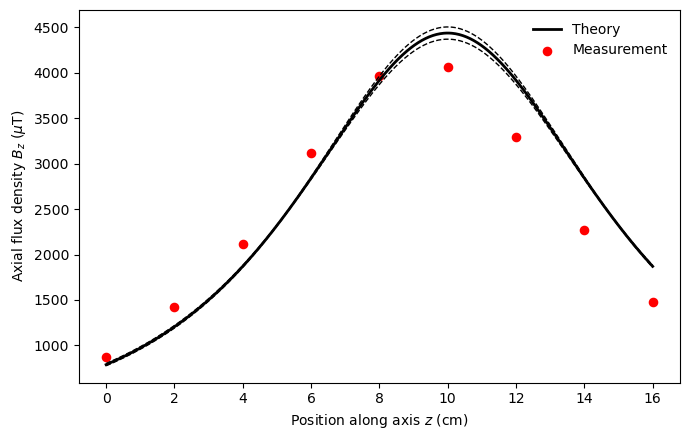

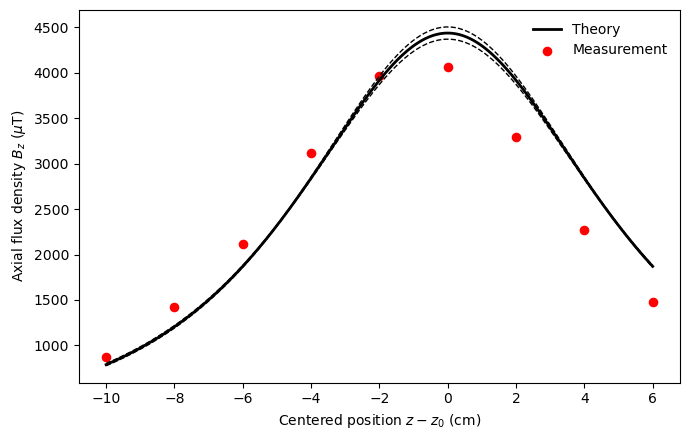

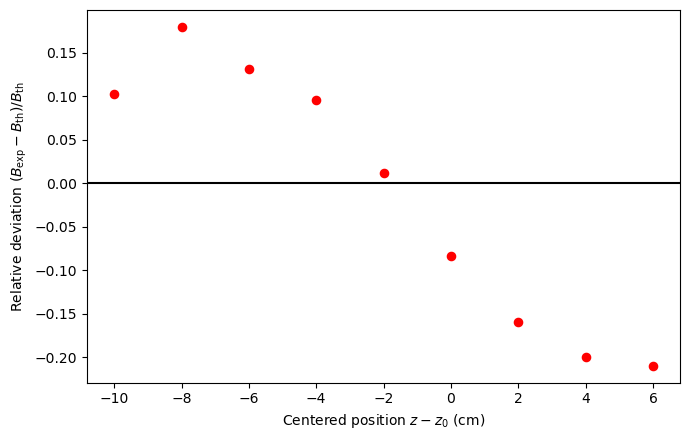

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# 0) Constants and coil params
# -----------------------------
mu0 = 4*np.pi*1e-7  # H/m

# Pair of coils 3 (manual table): two identical flat coils
# For Task 2 we use ONE coil of the pair.
R0 = 68e-3   # m
N  = 320

# Uncertainties from manual
rel_u_geom = 0.015  # 1.5% relative uncertainty for geometric constants (here: R)

# Power supply current uncertainty (manual): ±(0.05% + 3 mA)
def u_I_supply(I_A: float) -> float:
    return 0.0005*I_A + 0.003  # A

# Sensor resolution (manual): 16-bit, configured to ±50 mT => span = 100 mT
# LSB = 100 mT / 65536 = 1.5259 µT
lsb_uT = 100e3 / 65536  # µT
u_B_sensor_uT = 0.5 * lsb_uT  # µT (effective reading uncertainty)

print(f"Sensor LSB ≈ {lsb_uT:.3f} µT, using u_B_sensor ≈ {u_B_sensor_uT:.3f} µT per reading")

# ---------------------------------
# 1) Load CSV robustly + parse data
# ---------------------------------
csv_path = "Task 2.csv"  # adjust if needed

for sep in [",", ";", "\t"]:
    try:
        df_raw = pd.read_csv(csv_path, sep=sep)
        if df_raw.shape[1] >= 2:
            break
    except Exception:
        continue

df = df_raw.copy()
df.columns = [c.strip() for c in df.columns]

# Identify columns (your screenshot: "position y", "B(y)", "current")
pos_col = [c for c in df.columns if "position" in c.lower()][0]
B_col   = [c for c in df.columns if "b" in c.lower()][0]
I_col   = [c for c in df.columns if "curr" in c.lower()][0]  # "current"

# Find background row
bg_mask = df[pos_col].astype(str).str.lower().str.contains("background")
if bg_mask.any():
    B_bg_uT = float(df.loc[bg_mask, B_col].iloc[0])
else:
    raise ValueError("Couldn't find a background row. Ensure one row contains 'background' in the position column.")

# Numeric measurement rows
df_meas = df.loc[~bg_mask].copy()
df_meas[pos_col] = pd.to_numeric(df_meas[pos_col], errors="coerce")
df_meas[B_col]   = pd.to_numeric(df_meas[B_col], errors="coerce")
df_meas[I_col]   = pd.to_numeric(df_meas[I_col], errors="coerce")
df_meas = df_meas.dropna(subset=[pos_col, B_col]).sort_values(pos_col).reset_index(drop=True)

z_cm = df_meas[pos_col].to_numpy()
z_m  = z_cm * 1e-2

B_meas_uT = df_meas[B_col].to_numpy()
B_corr_uT = B_meas_uT - B_bg_uT

# Use mean current from file (should be constant 1.5 A)
I_A = float(np.mean(df_meas[I_col]))

print(f"Background field: {B_bg_uT:.3f} µT")
print(f"Using current I = {I_A:.4f} A")
print(df_meas[[pos_col, B_col, I_col]])

# -------------------------------------------------
# 2) Theory: axial field of a flat circular coil
# -------------------------------------------------
def Bz_single_flat_coil(z_m, I_A, R_m, N_turns):
    """Axial flux density of a flat circular coil (N turns, radius R)."""
    return (mu0 * I_A * N_turns * R_m**2) / (2.0 * (R_m**2 + z_m**2)**(1.5))  # Tesla

# Important: your z=0 is the LEFT END reference, not the coil center.
# We must determine the coil center position z0 from the maximum field:
idx_max = int(np.argmax(B_corr_uT))
z0_cm = float(z_cm[idx_max])
z0_m  = z0_cm * 1e-2

# Define centered coordinate relative to coil center:
z_rel_m  = z_m - z0_m
z_rel_cm = z_rel_m * 100

print(f"Estimated coil center at z0 ≈ {z0_cm:.2f} cm (position of maximum B)")

# Theoretical curve on a dense centered grid for plotting
z_rel_grid_m = np.linspace(np.min(z_rel_m), np.max(z_rel_m), 600)
B_th_T = Bz_single_flat_coil(z_rel_grid_m, I_A, R0, N)
B_th_uT = B_th_T * 1e6

# -------------------------------------------------
# 3) Uncertainties: Monte Carlo for theory
# -------------------------------------------------
rng = np.random.default_rng(0)
n_mc = 20000

R_samp = rng.normal(R0, rel_u_geom*R0, size=n_mc)
uI = u_I_supply(I_A)
I_samp = rng.normal(I_A, uI, size=n_mc)

# Compute theory band on grid
B_mc = np.empty((n_mc, z_rel_grid_m.size), dtype=float)
for k in range(n_mc):
    Rk = max(R_samp[k], 1e-9)
    Ik = max(I_samp[k], 0.0)
    B_mc[k, :] = Bz_single_flat_coil(z_rel_grid_m, Ik, Rk, N)

B_th_mean_uT = B_mc.mean(axis=0) * 1e6
B_th_std_uT  = B_mc.std(axis=0, ddof=1) * 1e6

# -------------------------------------------------
# 4) Experimental uncertainties (sensor + bg subtraction)
# -------------------------------------------------
# Background measured once with same sensor => subtraction adds in quadrature
u_Bcorr_uT = np.sqrt(u_B_sensor_uT**2 + u_B_sensor_uT**2)

# -------------------------------------------------
# 5) Task 2c: Half-maximum distance (experimental + theory)
# -------------------------------------------------
# Experimental: determine Bmax and solve for |z - z0| where B = 0.5 Bmax
Bmax_uT = float(np.max(B_corr_uT))
half_uT = 0.5 * Bmax_uT

# Work on the right side of the center (z_rel >= 0) to find the first crossing
mask_right = z_rel_m >= 0
zR = z_rel_m[mask_right]
BR = B_corr_uT[mask_right]

# Ensure monotonic decrease after maximum: use points from the max index onward within right side
# Find the index of max within right-side arrays:
idx_max_right = int(np.argmax(BR))
zR2 = zR[idx_max_right:]
BR2 = BR[idx_max_right:]

# Find crossing with half value using linear interpolation between neighboring points
def find_crossing(z_arr, y_arr, y_target):
    for i in range(len(y_arr) - 1):
        y1, y2 = y_arr[i], y_arr[i+1]
        if (y1 >= y_target and y2 <= y_target) or (y1 <= y_target and y2 >= y_target):
            # linear interpolation
            z1, z2 = z_arr[i], z_arr[i+1]
            if y2 == y1:
                return float(z1)
            return float(z1 + (y_target - y1) * (z2 - z1) / (y2 - y1))
    return np.nan

z_half_exp_m = find_crossing(zR2, BR2, half_uT)
z_half_exp_cm = z_half_exp_m * 100

# Theoretical: B(z)/B(0)=1/2 gives (R^2+z^2)^(3/2)=2 R^3 => z = R*sqrt(2^(2/3)-1)
z_half_th_m = R0 * np.sqrt(2**(2/3) - 1)
z_half_th_cm = z_half_th_m * 100

# Uncertainties:
# Experimental half position uncertainty: estimate via propagation from B uncertainty and local slope.
# z_half = f(B), approximate u_z ≈ u_B / |dB/dz| at crossing (use local slope from the two points around crossing)
def estimate_u_z_from_slope(z_arr, y_arr, y_target, u_y):
    for i in range(len(y_arr) - 1):
        y1, y2 = y_arr[i], y_arr[i+1]
        if (y1 >= y_target and y2 <= y_target) or (y1 <= y_target and y2 >= y_target):
            z1, z2 = z_arr[i], z_arr[i+1]
            slope = (y2 - y1) / (z2 - z1)  # µT per m
            if slope == 0:
                return np.nan
            return float(abs(u_y / slope))
    return np.nan

u_zhalf_exp_m = estimate_u_z_from_slope(zR2, BR2, half_uT, u_Bcorr_uT)
u_zhalf_exp_cm = u_zhalf_exp_m * 100 if np.isfinite(u_zhalf_exp_m) else np.nan

# Theoretical half position uncertainty from R uncertainty only (dominant) + current cancels in ratio
# z_half_th = k * R with k = sqrt(2^(2/3)-1)
k = np.sqrt(2**(2/3) - 1)
u_R = rel_u_geom * R0
u_zhalf_th_m = k * u_R
u_zhalf_th_cm = u_zhalf_th_m * 100

print("\n--- Task 2 key results ---")
print(f"Coil center (from max): z0 = {z0_cm:.2f} cm")
print(f"B_max (corr.) = {Bmax_uT:.2f} µT, half = {half_uT:.2f} µT")
print(f"Half-maximum distance (exp.):  z_1/2 = {z_half_exp_cm:.2f} ± {u_zhalf_exp_cm:.2f} cm (from center, right side)")
print(f"Half-maximum distance (theory): z_1/2 = {z_half_th_cm:.2f} ± {u_zhalf_th_cm:.2f} cm")

# -------------------------------------------------
# 6) Plot 1: Bz vs position (absolute), with theory centered + shifted back, save PNG
# -------------------------------------------------
# To overlay theory on the absolute coordinate, we shift the theoretical centered curve by z0:
z_abs_grid_cm = (z_rel_grid_m + z0_m) * 100

plt.figure(figsize=(7,4.5))

# Theory mean (black line)
plt.plot(z_abs_grid_cm, B_th_mean_uT, color="black", linewidth=2, label="Theory")
# Theory ±1σ (black dashed)
plt.plot(z_abs_grid_cm, B_th_mean_uT + B_th_std_uT, color="black", linestyle="--", linewidth=1)
plt.plot(z_abs_grid_cm, B_th_mean_uT - B_th_std_uT, color="black", linestyle="--", linewidth=1)

# Experimental points (red)
plt.scatter(z_cm, B_corr_uT, color="red", s=35, label="Measurement")

plt.xlabel(r"Position along axis $z$ (cm)")
plt.ylabel(r"Axial flux density $B_z$ ($\mu$T)")
plt.legend(frameon=False)
plt.tight_layout()

plt.savefig("task2_Bz_vs_z.png", dpi=300)
plt.show()

# -------------------------------------------------
# 7) Plot 2: Centered plot Bz vs z_rel (good for symmetry), save PNG
# -------------------------------------------------
plt.figure(figsize=(7,4.5))

plt.plot(z_rel_grid_m*100, B_th_mean_uT, color="black", linewidth=2, label="Theory")
plt.plot(z_rel_grid_m*100, B_th_mean_uT + B_th_std_uT, color="black", linestyle="--", linewidth=1)
plt.plot(z_rel_grid_m*100, B_th_mean_uT - B_th_std_uT, color="black", linestyle="--", linewidth=1)

plt.scatter(z_rel_cm, B_corr_uT, color="red", s=35, label="Measurement")

plt.xlabel(r"Centered position $z-z_0$ (cm)")
plt.ylabel(r"Axial flux density $B_z$ ($\mu$T)")
plt.legend(frameon=False)
plt.tight_layout()

plt.savefig("task2_Bz_centered.png", dpi=300)
plt.show()

# -------------------------------------------------
# 8) Plot 3: Relative deviation vs centered position, save PNG
# -------------------------------------------------
# Interpolate theory onto measurement points (centered)
B_th_on_meas_uT = np.interp(z_rel_m, z_rel_grid_m, B_th_mean_uT)
rel_dev = (B_corr_uT - B_th_on_meas_uT) / B_th_on_meas_uT

plt.figure(figsize=(7,4.5))
plt.axhline(0.0, color="black", linewidth=1.5)
plt.scatter(z_rel_cm, rel_dev, color="red", s=35)

plt.xlabel(r"Centered position $z-z_0$ (cm)")
plt.ylabel(r"Relative deviation $(B_{\mathrm{exp}}-B_{\mathrm{th}})/B_{\mathrm{th}}$")
plt.tight_layout()

plt.savefig("task2_relative_deviation.png", dpi=300)
plt.show()

Sensor LSB ≈ 1.526 µT, u_B_sensor ≈ 0.763 µT, u_Bcorr ≈ 1.079 µT
Raw shape: (26, 11)

Preview (first 6 rows):


,0,1,2,3,4,5,6,7,8,9,10
0,Set 1,b = 13.6 (2R),NaN,NaN,Set 2,b = 6.8 (R),NaN,NaN,Set 3,b = 3.4 (R/2),NaN
1,position y,B (y),current,NaN,position y,B (y),current,NaN,position y,B (y),current
2,0,981.3,1.5,NaN,0,1092.6,1.5,NaN,0,1032.6,1.5
3,1,1209,1.5,NaN,1,1347.3,1.5,NaN,1,1272.9,1.5
4,2,1463.1,1.5,NaN,2,1640.4,1.5,NaN,2,1606.8,1.5
5,3,1735.8,1.5,NaN,3,1968.3,1.5,NaN,3,1975.8,1.5


Set 1 (b=2R): bg=3.600 µT, I=1.500 A, midpoint=11.0 cm, n=22
Set 2 (b=R, Helmholtz): bg=3.000 µT, I=1.500 A, midpoint=8.0 cm, n=16
Set 3 (b=R/2): bg=1.500 µT, I=1.500 A, midpoint=8.0 cm, n=16


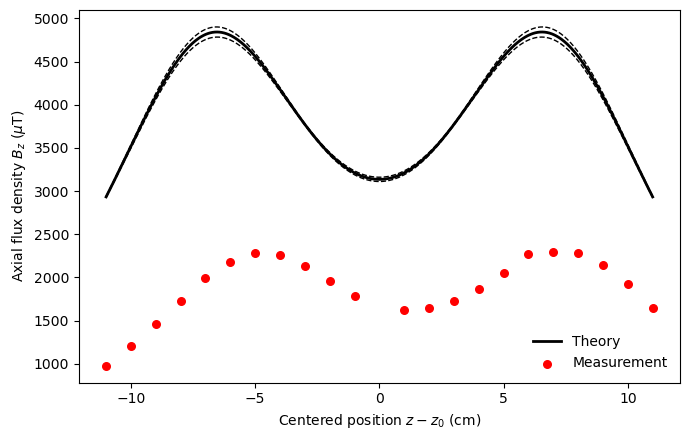

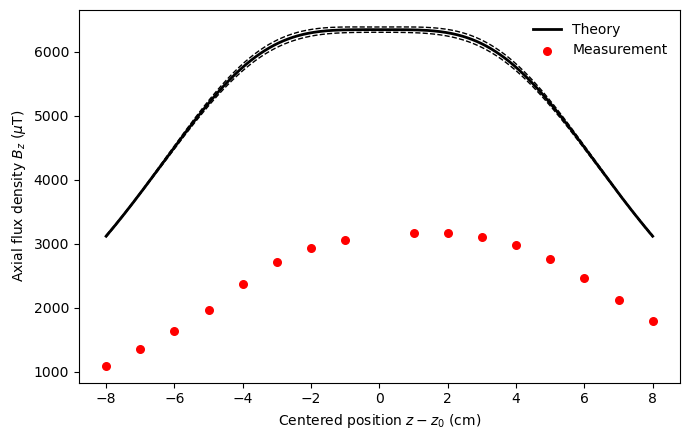

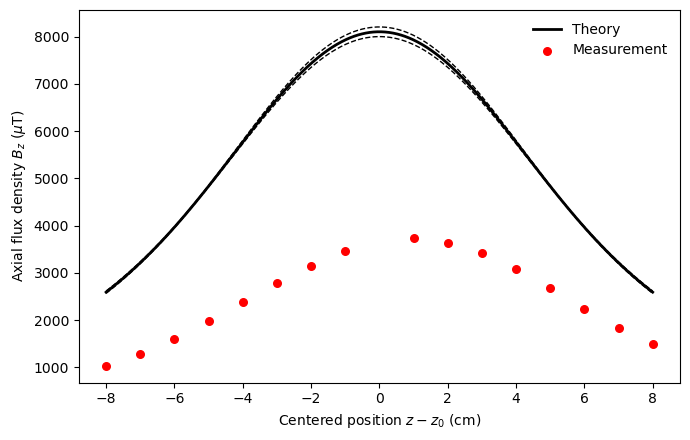

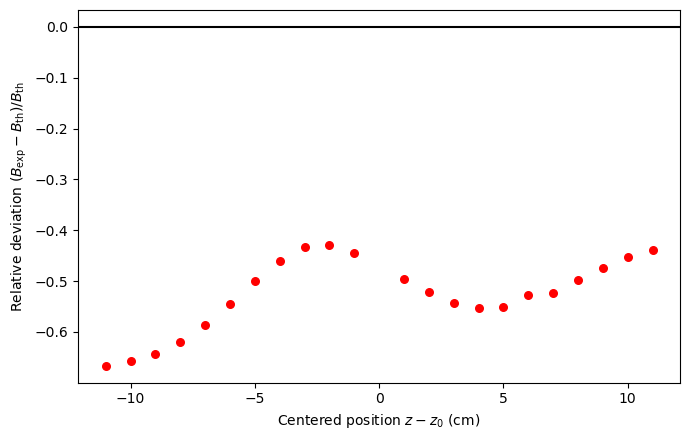

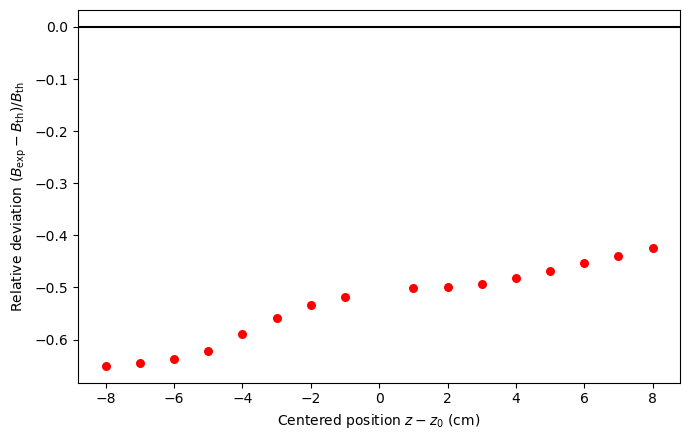

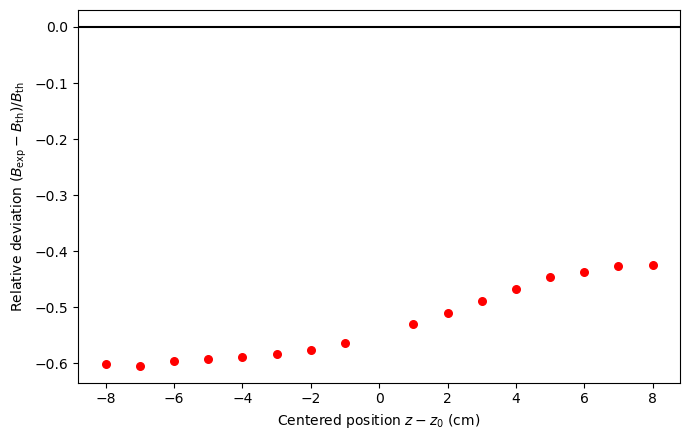


--- Helmholtz (b=R) homogeneity region |ΔB|/B0 < 5% ---
Theory: B0 ≈ 6346.93 µT, region [-3.31, 3.31] cm centered
Exp.:   B0 ≈ 3112.50 µT, region [-1.80, 4.11] cm centered


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# 0) Constants and coil params
# -----------------------------
mu0 = 4*np.pi*1e-7  # H/m

# Pair of coils 3 parameters
R0 = 68e-3
N  = 320

b_2R = 2*R0
b_R  = 1*R0
b_R2 = 0.5*R0

# Midpoints (absolute position in cm)
z0_set1_cm = 11.0  # b=2R
z0_set2_cm = 8.0   # b=R
z0_set3_cm = 8.0   # b=R/2

# Uncertainties
rel_u_geom = 0.015

def u_I_supply(I_A: float) -> float:
    return 0.0005*I_A + 0.003  # A

lsb_uT = 100e3 / 65536
u_B_sensor_uT = 0.5 * lsb_uT
u_Bcorr_uT = np.sqrt(u_B_sensor_uT**2 + u_B_sensor_uT**2)

print(f"Sensor LSB ≈ {lsb_uT:.3f} µT, u_B_sensor ≈ {u_B_sensor_uT:.3f} µT, u_Bcorr ≈ {u_Bcorr_uT:.3f} µT")

# -----------------------------------------
# 1) Read CSV WITHOUT assuming headers
# -----------------------------------------
csv_path = "Task 3.csv"

# Try common separators, no header
df = None
for sep in [",", ";", "\t"]:
    try:
        tmp = pd.read_csv(csv_path, sep=sep, header=None)
        # We expect a wide table (>= 9 columns)
        if tmp.shape[1] >= 9:
            df = tmp
            break
    except Exception:
        pass

if df is None:
    raise RuntimeError("Could not read Task 3.csv. Check delimiter or file path.")

print("Raw shape:", df.shape)
print("\nPreview (first 6 rows):")
display(df.head(6))

# -----------------------------------------
# 2) Extract blocks by COLUMN INDEX
# Based on your screenshot layout:
# Set 1 uses columns 0,1,2
# Set 2 uses columns 4,5,6
# Set 3 uses columns 8,9,10
# (there are blank separator columns between them)
# -----------------------------------------

def extract_block(df, c_pos, c_B, c_I, midpoint_cm, label):
    # Grab the three columns
    block = df[[c_pos, c_B, c_I]].copy()

    # Remove the first two header rows if they exist (usually "Set 1", "position y", etc.)
    # We'll detect numeric rows by converting position to numeric.
    block.columns = ["pos", "B", "I"]
    block["pos_str"] = block["pos"].astype(str).str.strip().str.lower()

    # Find background row
    bg_mask = block["pos_str"].str.contains("background")
    if not bg_mask.any():
        raise ValueError(f"Background row not found for {label} (expected 'background' in position column).")

    B_bg_uT = float(pd.to_numeric(block.loc[bg_mask, "B"], errors="coerce").iloc[0])

    # Numeric measurement rows
    d = block.loc[~bg_mask, ["pos", "B", "I"]].copy()
    d["pos"] = pd.to_numeric(d["pos"], errors="coerce")
    d["B"]   = pd.to_numeric(d["B"], errors="coerce")
    d["I"]   = pd.to_numeric(d["I"], errors="coerce")

    d = d.dropna(subset=["pos", "B"]).sort_values("pos").reset_index(drop=True)

    z_cm = d["pos"].to_numpy(float)
    z_m  = z_cm * 1e-2
    B_uT = d["B"].to_numpy(float)
    I_A  = float(np.nanmean(d["I"].to_numpy(float)))

    B_corr_uT = B_uT - B_bg_uT

    z0_m = midpoint_cm * 1e-2
    z_rel_m = z_m - z0_m

    print(f"{label}: bg={B_bg_uT:.3f} µT, I={I_A:.3f} A, midpoint={midpoint_cm:.1f} cm, n={len(z_cm)}")

    return dict(
        label=label,
        B_bg_uT=B_bg_uT,
        I_A=I_A,
        z_cm=z_cm, z_m=z_m,
        z0_cm=midpoint_cm, z0_m=z0_m,
        z_rel_m=z_rel_m,
        B_uT=B_uT,
        B_corr_uT=B_corr_uT
    )

set1 = extract_block(df, 0, 1, 2, z0_set1_cm, "Set 1 (b=2R)")
set2 = extract_block(df, 4, 5, 6, z0_set2_cm, "Set 2 (b=R, Helmholtz)")
set3 = extract_block(df, 8, 9, 10, z0_set3_cm, "Set 3 (b=R/2)")

# -------------------------------------------------
# 3) Theory: pair of coils
# -------------------------------------------------
def Bz_pair(z_rel_m, I_A, R_m, N_turns, b_m):
    term1 = 1.0 / (R_m**2 + (z_rel_m - b_m/2)**2)**(1.5)
    term2 = 1.0 / (R_m**2 + (z_rel_m + b_m/2)**2)**(1.5)
    return (mu0 * I_A * N_turns * R_m**2 / 2.0) * (term1 + term2)  # Tesla

# -------------------------------------------------
# 4) Monte Carlo theory band
# -------------------------------------------------
rng = np.random.default_rng(0)
n_mc = 20000

def theory_band(z_grid, I_A, b_m):
    R_samp = rng.normal(R0, rel_u_geom*R0, size=n_mc)
    I_samp = rng.normal(I_A, u_I_supply(I_A), size=n_mc)

    B_mc = np.empty((n_mc, z_grid.size))
    for k in range(n_mc):
        Rk = max(R_samp[k], 1e-9)
        Ik = max(I_samp[k], 0.0)
        B_mc[k, :] = Bz_pair(z_grid, Ik, Rk, N, b_m)

    mean_uT = B_mc.mean(axis=0)*1e6
    std_uT  = B_mc.std(axis=0, ddof=1)*1e6
    return mean_uT, std_uT

# -------------------------------------------------
# 5) Plot helpers
# -------------------------------------------------
def plot_meas_vs_theory(s, b_m, fname):
    z = s["z_rel_m"]
    B = s["B_corr_uT"]
    I_A = s["I_A"]

    z_grid = np.linspace(np.min(z), np.max(z), 700)
    th_mean, th_std = theory_band(z_grid, I_A, b_m)

    plt.figure(figsize=(7,4.5))
    plt.plot(z_grid*100, th_mean, color="black", linewidth=2, label="Theory")
    plt.plot(z_grid*100, th_mean+th_std, color="black", linestyle="--", linewidth=1)
    plt.plot(z_grid*100, th_mean-th_std, color="black", linestyle="--", linewidth=1)
    plt.scatter(z*100, B, color="red", s=30, label="Measurement")

    plt.xlabel(r"Centered position $z-z_0$ (cm)")
    plt.ylabel(r"Axial flux density $B_z$ ($\mu$T)")
    plt.legend(frameon=False)
    plt.tight_layout()
    plt.savefig(fname, dpi=300)
    plt.show()

    return z_grid, th_mean

def plot_rel_dev(s, z_grid, th_mean, fname):
    z = s["z_rel_m"]
    B = s["B_corr_uT"]
    th_on_meas = np.interp(z, z_grid, th_mean)
    rel = (B - th_on_meas) / th_on_meas

    plt.figure(figsize=(7,4.5))
    plt.axhline(0, color="black", linewidth=1.5)
    plt.scatter(z*100, rel, color="red", s=30)

    plt.xlabel(r"Centered position $z-z_0$ (cm)")
    plt.ylabel(r"Relative deviation $(B_{\mathrm{exp}}-B_{\mathrm{th}})/B_{\mathrm{th}}$")
    plt.tight_layout()
    plt.savefig(fname, dpi=300)
    plt.show()

# -------------------------------------------------
# 6) Generate required plots
# -------------------------------------------------
z1, th1 = plot_meas_vs_theory(set1, b_2R, "task3_set1_b_2R.png")
z2, th2 = plot_meas_vs_theory(set2, b_R,  "task3_set2_b_R_helmholtz.png")
z3, th3 = plot_meas_vs_theory(set3, b_R2, "task3_set3_b_R2.png")

plot_rel_dev(set1, z1, th1, "task3_rel_dev_set1.png")
plot_rel_dev(set2, z2, th2, "task3_rel_dev_set2.png")
plot_rel_dev(set3, z3, th3, "task3_rel_dev_set3.png")

# -------------------------------------------------
# 7) Helmholtz homogeneity region (±5%)
# -------------------------------------------------
def homogeneity_region_theory(z_grid, th_mean, threshold=0.05):
    B0 = float(np.interp(0.0, z_grid, th_mean))
    rel = np.abs(th_mean - B0)/B0
    mask = rel < threshold

    i0 = int(np.argmin(np.abs(z_grid)))
    if not mask[i0]:
        return np.nan, np.nan, B0

    iL = i0
    while iL > 0 and mask[iL-1]:
        iL -= 1
    iR = i0
    while iR < len(mask)-1 and mask[iR+1]:
        iR += 1

    return float(z_grid[iL]), float(z_grid[iR]), B0

def homogeneity_region_exp(z_rel, B_corr, threshold=0.05):
    z_grid = np.linspace(np.min(z_rel), np.max(z_rel), 2000)
    B_grid = np.interp(z_grid, np.sort(z_rel), B_corr[np.argsort(z_rel)])
    B0 = float(np.interp(0.0, z_grid, B_grid))
    rel = np.abs(B_grid - B0)/B0
    mask = rel < threshold

    i0 = int(np.argmin(np.abs(z_grid)))
    if not mask[i0]:
        return np.nan, np.nan, B0

    iL = i0
    while iL > 0 and mask[iL-1]:
        iL -= 1
    iR = i0
    while iR < len(mask)-1 and mask[iR+1]:
        iR += 1

    return float(z_grid[iL]), float(z_grid[iR]), B0

zL_th, zR_th, B0_th = homogeneity_region_theory(z2, th2, threshold=0.05)
zL_ex, zR_ex, B0_ex = homogeneity_region_exp(set2["z_rel_m"], set2["B_corr_uT"], threshold=0.05)

print("\n--- Helmholtz (b=R) homogeneity region |ΔB|/B0 < 5% ---")
print(f"Theory: B0 ≈ {B0_th:.2f} µT, region [{zL_th*100:.2f}, {zR_th*100:.2f}] cm centered")
print(f"Exp.:   B0 ≈ {B0_ex:.2f} µT, region [{zL_ex*100:.2f}, {zR_ex*100:.2f}] cm centered")
